# Eksplorasi Data: Security Awareness Perusahaan di Indonesia

**Mata kuliah:** Data Mining · **Fokus minggu ini:** mengenal data dulu (*knowledge*) sebelum memilih algoritma.

| Tahap | Isi notebook |
|---|---|
| 1. Data & Loading | Membaca data dari CSV, Excel, JSON, HTML, XML, SQL, dan GitHub |
| 2. Eksplorasi Data | (1) Jenis data kategorikal vs numerikal · (2) Tipe data kategorikal · (3) Jumlah duplikat & null |
| 3. Merapikan Data | Hapus duplikat, isi null dengan aturan yang bisa dipertanggungjawabkan, set tipe data |
| 4. Pratinjau Insight | Pola awal yang akan diuji dengan algoritma minggu depan |

> ⚠️ **Data sintetis.** Dataset dibuat dengan `generate_dataset.py` (seed 42) untuk latihan. Kategori dan ambang nilai
> mengikuti regulasi resmi (UU PDP, Indeks KAMI BSSN, PP 7/2021), tetapi angkanya **bukan** data perusahaan nyata.
> Daftar referensi ada di `README.md`.

## 0. Setup

In [1]:
# Jika belum terpasang:
# !pip install pandas openpyxl lxml matplotlib

from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

print("pandas versi :", pd.__version__)
print("numpy versi  :", np.__version__)

DATA = Path("data")
RAW = DATA / "security_awareness_indonesia.csv"

pandas versi : 3.0.5
numpy versi  : 2.5.3


In [2]:
# Gaya grafik: satu warna utama, grid tipis, teks abu tua
BIRU, ABU = "#2a78d6", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": ABU, "xtick.color": ABU, "ytick.color": ABU,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

## 1. Data & Loading

Dataset aslinya berupa **CSV**. Supaya bisa latihan semua fungsi `read_*` pandas, sel di bawah membuat salinan data
yang sama dalam format Excel, JSON, HTML, XML, dan SQLite di folder `data/format/`. Setelah itu tiap format dibaca
kembali — hasilnya harus identik: **5.120 baris × 55 kolom**.

In [3]:
df_awal = pd.read_csv(RAW, dtype={"kode_pos": "string"})

FMT = DATA / "format"
FMT.mkdir(exist_ok=True)
df_awal.to_excel(FMT / "security_awareness.xlsx", index=False, sheet_name="data")
df_awal.to_json(FMT / "security_awareness.json", orient="records", indent=1, force_ascii=False)
df_awal.to_html(FMT / "security_awareness.html", index=False)
df_awal.to_xml(FMT / "security_awareness.xml", index=False, root_name="perusahaan_list", row_name="perusahaan")
with sqlite3.connect(FMT / "security_awareness.db") as con:
    df_awal.to_sql("security_awareness", con, if_exists="replace", index=False)

sorted(p.name for p in FMT.iterdir())

['security_awareness.db',
 'security_awareness.html',
 'security_awareness.json',
 'security_awareness.xlsx',
 'security_awareness.xml']

### 1.1 `read_csv` — format paling umum

In [4]:
df_csv = pd.read_csv(RAW, dtype={"kode_pos": "string"})  # kode pos = label, bukan angka
df_csv.shape

(5120, 55)

### 1.2 `read_excel` — butuh library `openpyxl`

In [5]:
df_excel = pd.read_excel(FMT / "security_awareness.xlsx", sheet_name="data")
df_excel.shape

(5120, 55)

### 1.3 `read_json` — format umum untuk API

In [6]:
df_json = pd.read_json(FMT / "security_awareness.json", orient="records")
df_json.shape

(5120, 55)

### 1.4 `read_html` — membaca tabel `<table>` dari halaman web (hasilnya *list* of DataFrame)

In [7]:
tabel_html = pd.read_html(FMT / "security_awareness.html")
print("Jumlah tabel ditemukan:", len(tabel_html))
df_html = tabel_html[0]
df_html.shape

Jumlah tabel ditemukan: 1


(5120, 55)

### 1.5 `read_xml` — butuh library `lxml`

In [8]:
df_xml = pd.read_xml(FMT / "security_awareness.xml", xpath="//perusahaan")
df_xml.shape

(5120, 55)

### 1.6 `read_sql` — membaca hasil query dari database (contoh: SQLite)

In [9]:
with sqlite3.connect(FMT / "security_awareness.db") as con:
    df_sql = pd.read_sql("SELECT * FROM security_awareness", con)
    # Query SQL juga bisa langsung memfilter:
    contoh = pd.read_sql(
        "SELECT sektor, COUNT(*) AS jumlah FROM security_awareness GROUP BY sektor ORDER BY jumlah DESC LIMIT 3", con)
print(df_sql.shape)
contoh

(5120, 55)


,sektor,jumlah
0,Manufaktur,572
1,Teknologi Informasi,508
2,Perbankan,507


### 1.7 Membaca dari GitHub

Pakai URL **raw** (bukan URL halaman GitHub biasa). Sumber: repo `NullIvy/datamining_04TPLE001`.

In [ ]:
URL_GITHUB = "https://raw.githubusercontent.com/NullIvy/datamining_04TPLE001/main/security-awareness/data/security_awareness_indonesia.csv"

try:
    df_github = pd.read_csv(URL_GITHUB)
    print("Berhasil dari GitHub:", df_github.shape)
except Exception as e:
    df_github = None
    print("Belum bisa dibaca dari GitHub (cek URL/koneksi):", type(e).__name__)

Berhasil dari GitHub: (5120, 55)


### 1.8 Cek: semua format menghasilkan data yang sama

In [11]:
hasil = {"CSV": df_csv, "Excel": df_excel, "JSON": df_json, "HTML": df_html, "XML": df_xml, "SQL": df_sql}
if df_github is not None:
    hasil["GitHub"] = df_github

pd.DataFrame({
    "baris": {k: v.shape[0] for k, v in hasil.items()},
    "kolom": {k: v.shape[1] for k, v in hasil.items()},
    "sel_kosong": {k: int(v.isna().sum().sum()) for k, v in hasil.items()},
})

,baris,kolom,sel_kosong
CSV,5120,55,4851
Excel,5120,55,4851
JSON,5120,55,4851
HTML,5120,55,4851
XML,5120,55,4851
SQL,5120,55,4851
GitHub,5120,55,4851


## 2. Eksplorasi Data

Mulai sekarang kita pakai `df` = data mentah dari CSV.

In [12]:
df = df_csv.copy()
print(f"{df.shape[0]:,} baris × {df.shape[1]} kolom")
df.head()

5,120 baris × 55 kolom


,id_perusahaan,nama_perusahaan,sektor,status_kepemilikan,provinsi,kota,kode_pos,latitude,longitude,skala_usaha,jumlah_karyawan,omzet_tahunan_miliar_rp,tahun_berdiri,jumlah_cabang,kategori_sistem_elektronik,memiliki_tim_keamanan,jumlah_staf_keamanan_it,memiliki_soc,status_iso27001,kebijakan_keamanan_tertulis,kepatuhan_uu_pdp,memiliki_dpo,anggaran_keamanan_persen_it,asuransi_siber,program_bug_bounty,...,rata2_hari_patching,frekuensi_backup,frekuensi_pelatihan_per_tahun,metode_pelatihan,persen_karyawan_terlatih,simulasi_phishing_per_tahun,phishing_click_rate_persen,phishing_report_rate_persen,jumlah_laporan_phishing_karyawan,penerapan_mfa,kebijakan_password,persen_password_bocor,skor_indeks_kami,kategori_indeks_kami,jumlah_insiden_12_bulan,jenis_insiden_utama,motif_serangan_utama,vektor_serangan_awal,penyebab_utama_insiden,waktu_deteksi_jam,lama_downtime_jam,estimasi_kerugian_juta_rp,skor_awareness,tingkat_awareness,tanggal_survei
0,SA-00531,PT Wahana Retail Sejahtera,Ritel & E-commerce,Terbuka (Tbk),Banten,Tangerang Selatan,15827,-6.27464,106.71097,Besar,1170.0,639.90,1977,14,Rendah,Tidak,0,Outsource (MSSP),Belum,Ya,Sebagian,Ya,13.8,Tidak,Tidak,...,NaN,Mingguan,10,Tatap Muka,73.8,3,11.8,43.9,156,Penuh,Sedang,3.6,484,Cukup Baik,0,Tidak Ada,Tidak Ada,Tidak Ada,Tidak Ada,NaN,0.0,0.0,79.5,Sedang,2026-03-05
1,SA-01730,PT Wira Data Gemilang,Telekomunikasi,BUMN/BUMD,Jawa Barat,Bogor,16588,-6.61504,106.81485,Besar,250.0,130.81,2003,9,Strategis,Ya,7,Tidak Ada,Tersertifikasi,Ya,Patuh,Tidak,3.3,Tidak,Tidak,...,38.0,Mingguan,9,E-Learning,69.7,3,19.6,44.5,26,Tidak,Kuat,6.6,461,Pemenuhan Kerangka Kerja Dasar,2,Malware,Finansial,Email Phishing,Kesalahan Manusia,124.8,10.3,389.6,71.8,Sedang,2026-04-24
2,SA-01011,PT Harapan Finansial Lestari,Pemerintahan & BUMN Jasa,BUMN/BUMD,Jawa Barat,Bandung,40940,-6.93205,107.61895,Kecil,32.0,10.10,2015,0,Strategis,Tidak,0,Tidak Ada,Dalam Proses,Tidak,Sebagian,Tidak,7.7,Tidak,Tidak,...,37.0,Bulanan,5,Gamifikasi,64.6,3,8.7,41.9,7,Tidak,Sedang,10.8,337,Pemenuhan Kerangka Kerja Dasar,2,Phishing,Finansial,Email Phishing,Kesalahan Manusia,233.0,9.8,6.3,59.5,Rendah,2026-07-19
3,SA-01150,PT Mega Trans Nusantara,Logistik & Transportasi,Swasta Nasional,Jawa Tengah,Kudus,59473,-6.83885,110.78399,Menengah,244.0,18.27,1991,1,Strategis,Ya,2,Tidak Ada,Belum,Ya,Patuh,Tidak,6.4,Tidak,Tidak,...,48.0,Tidak Ada,3,Tatap Muka,60.6,4,29.7,34.1,21,Sebagian,Sedang,8.8,283,Tidak Layak,2,Malware,Hacktivism,Email Phishing,Kredensial Dicuri,371.6,62.6,1358.5,42.2,Rendah,2026-09-24
4,SA-01384,PT Bumi Logistik Gemilang,Kesehatan,Swasta Nasional,DKI Jakarta,Jakarta Barat,11324,-6.14459,106.74997,Besar,405.0,127.43,1971,11,Tinggi,Tidak,0,Internal,Tersertifikasi,Tidak,Patuh,Ya,7.1,Tidak,Tidak,...,26.0,Bulanan,4,Tatap Muka,71.1,6,14.4,54.5,66,Sebagian,Lemah,5.1,514,Cukup Baik,3,Phishing,Finansial,Pihak Ketiga/Vendor,Pihak Ketiga,91.8,2.5,896.3,71.1,Sedang,2026-04-06


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5120 entries, 0 to 5119
Data columns (total 55 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id_perusahaan                     5120 non-null   str    
 1   nama_perusahaan                   5120 non-null   str    
 2   sektor                            5120 non-null   str    
 3   status_kepemilikan                5120 non-null   str    
 4   provinsi                          5120 non-null   str    
 5   kota                              5017 non-null   str    
 6   kode_pos                          4966 non-null   string 
 7   latitude                          4969 non-null   float64
 8   longitude                         4969 non-null   float64
 9   skala_usaha                       5120 non-null   str    
 10  jumlah_karyawan                   4967 non-null   float64
 11  omzet_tahunan_miliar_rp           4863 non-null   float64
 12  tahun_berdiri    

### Soal 1 — Bagi jenis data: Kategorikal & Numerikal

- **Numerikal** = berupa angka yang bisa dihitung (rata-rata, jumlah). Dibagi lagi:
  **diskret** (bilangan bulat hasil hitungan, mis. jumlah insiden) dan **kontinu** (hasil ukur, bisa desimal, mis. persentase).
- **Kategorikal** = label/kelompok. Dibagi lagi: **nominal** (tanpa urutan, mis. sektor),
  **ordinal** (punya urutan, mis. Rendah < Sedang < Tinggi), dan **biner** (dua nilai, mis. Ya/Tidak).

In [14]:
numerik = df.select_dtypes(include="number").columns.tolist()
kategorikal = df.select_dtypes(exclude="number").columns.tolist()

print(f"Numerikal   ({len(numerik)} kolom):", numerik, "\n")
print(f"Kategorikal ({len(kategorikal)} kolom):", kategorikal)

Numerikal   (26 kolom): ['latitude', 'longitude', 'jumlah_karyawan', 'omzet_tahunan_miliar_rp', 'tahun_berdiri', 'jumlah_cabang', 'jumlah_staf_keamanan_it', 'anggaran_keamanan_persen_it', 'persen_kerja_remote', 'persen_perangkat_byod', 'jumlah_vendor_ti', 'jumlah_akun_admin', 'rata2_hari_patching', 'frekuensi_pelatihan_per_tahun', 'persen_karyawan_terlatih', 'simulasi_phishing_per_tahun', 'phishing_click_rate_persen', 'phishing_report_rate_persen', 'jumlah_laporan_phishing_karyawan', 'persen_password_bocor', 'skor_indeks_kami', 'jumlah_insiden_12_bulan', 'waktu_deteksi_jam', 'lama_downtime_jam', 'estimasi_kerugian_juta_rp', 'skor_awareness'] 

Kategorikal (29 kolom): ['id_perusahaan', 'nama_perusahaan', 'sektor', 'status_kepemilikan', 'provinsi', 'kota', 'kode_pos', 'skala_usaha', 'kategori_sistem_elektronik', 'memiliki_tim_keamanan', 'memiliki_soc', 'status_iso27001', 'kebijakan_keamanan_tertulis', 'kepatuhan_uu_pdp', 'memiliki_dpo', 'asuransi_siber', 'program_bug_bounty', 'adopsi_clo

In [15]:
ORDINAL = ["skala_usaha", "kategori_sistem_elektronik", "status_iso27001", "kepatuhan_uu_pdp", "frekuensi_backup",
           "penerapan_mfa", "kebijakan_password", "kategori_indeks_kami", "tingkat_awareness"]
BINER = ["memiliki_tim_keamanan", "kebijakan_keamanan_tertulis", "memiliki_dpo", "asuransi_siber", "program_bug_bounty"]
IDENTITAS = ["id_perusahaan", "nama_perusahaan"]
TANGGAL = ["tanggal_survei"]

def sub_jenis(kolom):
    if kolom in IDENTITAS: return "Kategorikal - identitas (bukan fitur)"
    if kolom in TANGGAL:   return "Tanggal (disimpan sebagai teks)"
    if kolom in ORDINAL:   return "Kategorikal - ordinal"
    if kolom in BINER:     return "Kategorikal - biner"
    if kolom in kategorikal: return "Kategorikal - nominal"
    # numerik: kontinu jika ada nilai desimal, selain itu diskret
    desimal = (df[kolom].dropna() % 1 != 0).any()
    return "Numerikal - kontinu" if desimal or "persen" in kolom else "Numerikal - diskret"

jenis = pd.DataFrame({
    "kolom": df.columns,
    "dtype": [str(t) for t in df.dtypes],
    "jenis": [sub_jenis(c) for c in df.columns],
    "contoh_nilai": [df[c].dropna().iloc[0] for c in df.columns],
    "nilai_unik": [df[c].nunique() for c in df.columns],
})
jenis.sort_values(["jenis", "kolom"]).reset_index(drop=True)

,kolom,dtype,jenis,contoh_nilai,nilai_unik
0,asuransi_siber,str,Kategorikal - biner,Tidak,2
1,kebijakan_keamanan_tertulis,str,Kategorikal - biner,Ya,2
2,memiliki_dpo,str,Kategorikal - biner,Ya,2
3,memiliki_tim_keamanan,str,Kategorikal - biner,Tidak,2
4,program_bug_bounty,str,Kategorikal - biner,Tidak,2
5,id_perusahaan,str,Kategorikal - identitas (bukan fitur),SA-00531,5000
6,nama_perusahaan,str,Kategorikal - identitas (bukan fitur),PT Wahana Retail Sejahtera,5000
7,adopsi_cloud,str,Kategorikal - nominal,Hybrid,3
8,jenis_insiden_utama,str,Kategorikal - nominal,Tidak Ada,8
9,kode_pos,string,Kategorikal - nominal,15827,4384


In [16]:
jenis["jenis"].value_counts().to_frame("jumlah_kolom")

,jumlah_kolom
jenis,
Numerikal - kontinu,14
Kategorikal - nominal,12
Numerikal - diskret,12
Kategorikal - ordinal,9
Kategorikal - biner,5
Kategorikal - identitas (bukan fitur),2
Tanggal (disimpan sebagai teks),1


**Catatan:** `tanggal_survei` terbaca sebagai teks dan `tahun_berdiri` sebagai angka. Keduanya sebenarnya data waktu,
jadi perlu diputuskan perlakuannya — misalnya `tahun_berdiri` diubah menjadi `umur_perusahaan` saat modeling.

### Soal 2 — Data kategorikal pakai tipe apa? `float`? `void`?

Jawaban singkat: **bukan `float` dan bukan `void`.**

| Tipe | Dipakai untuk | Keterangan |
|---|---|---|
| `str` (pandas 3) / `object` (pandas < 3) | Teks/kategori saat baru dibaca | Default `read_csv` untuk kolom teks |
| `category` | Kategorikal yang sudah dirapikan | Hemat memori, bisa diberi **urutan** untuk data ordinal |
| `bool` | Biner Ya/Tidak | True/False |
| `int64` / `float64` | Numerikal | `float64` juga dipakai jika kolom angka punya NaN |
| `void` | **Tidak dipakai di pandas** | Istilah C/Java untuk "tidak ada nilai"; di NumPy `V` hanya untuk byte mentah |

Kategori yang diberi kode angka (mis. 1 = Rendah, 2 = Sedang) tetap **kategorikal**, karena angkanya hanya label.

In [17]:
df.dtypes.astype(str).value_counts().to_frame("jumlah_kolom")

,jumlah_kolom
str,28
float64,16
int64,10
string,1


In [18]:
# Bukti 1: kolom kategorikal terbaca sebagai teks (str/object), bukan float
df[["sektor", "skala_usaha", "tingkat_awareness"]].dtypes

sektor               str
skala_usaha          str
tingkat_awareness    str
dtype: object

In [19]:
# Bukti 2: ubah ke 'category' -> memori jauh lebih kecil
contoh = df["sektor"]
mem_teks = contoh.memory_usage(deep=True) / 1024
mem_cat = contoh.astype("category").memory_usage(deep=True) / 1024
print(f"sektor sebagai {contoh.dtype}  : {mem_teks:,.1f} KB")
print(f"sektor sebagai category : {mem_cat:,.1f} KB  (hemat {1 - mem_cat / mem_teks:.0%})")

sektor sebagai str  : 318.6 KB
sektor sebagai category : 5.9 KB  (hemat 98%)


In [20]:
# Bukti 3: kategori ordinal bisa punya urutan sehingga bisa dibandingkan
urut = pd.CategoricalDtype(["Rendah", "Sedang", "Tinggi"], ordered=True)
tingkat = df["tingkat_awareness"].astype(urut)
print(tingkat.dtype)
print("Jumlah perusahaan dengan awareness >= Sedang:", int((tingkat >= "Sedang").sum()))

category
Jumlah perusahaan dengan awareness >= Sedang: 3053


In [21]:
# Jebakan: jumlah_karyawan isinya bilangan bulat, tapi dtype-nya float64 karena ada NaN.
# Solusi tanpa menghapus NaN: tipe 'Int64' (huruf I besar) yang mendukung nilai kosong.
print("Sebelum :", df["jumlah_karyawan"].dtype)
print("Sesudah :", df["jumlah_karyawan"].astype("Int64").dtype)

Sebelum : float64
Sesudah : Int64


### Soal 3 — Berapa jumlah data duplikat & null?

In [22]:
n_dup = df.duplicated().sum()
n_null = int(df.isna().sum().sum())
print(f"Baris duplikat (persis sama)   : {n_dup}")
print(f"ID perusahaan yang berulang    : {df['id_perusahaan'].duplicated().sum()}")
print(f"Total sel null                 : {n_null:,} dari {df.size:,} sel ({n_null / df.size:.2%})")
print(f"Baris yang punya minimal 1 null: {df.isna().any(axis=1).sum():,} dari {len(df):,}")

Baris duplikat (persis sama)   : 120
ID perusahaan yang berulang    : 120
Total sel null                 : 4,851 dari 281,600 sel (1.72%)
Baris yang punya minimal 1 null: 3,182 dari 5,120


In [23]:
# Contoh baris duplikat (keep=False menampilkan aslinya juga)
df[df.duplicated(keep=False)].sort_values("id_perusahaan").head(6)[
    ["id_perusahaan", "nama_perusahaan", "sektor", "skor_awareness", "tanggal_survei"]]

,id_perusahaan,nama_perusahaan,sektor,skor_awareness,tanggal_survei
58,SA-00024,PT Nusa Solusi Abadi,Manufaktur,58.7,2026-07-31
2932,SA-00024,PT Nusa Solusi Abadi,Manufaktur,58.7,2026-07-31
161,SA-00030,PT Yasa Retail Jaya,Manufaktur,66.1,2026-04-02
1876,SA-00030,PT Yasa Retail Jaya,Manufaktur,66.1,2026-04-02
98,SA-00066,PT Kencana Industri Global,Teknologi Informasi,84.1,2026-05-10
1600,SA-00066,PT Kencana Industri Global,Teknologi Informasi,84.1,2026-05-10


In [24]:
null = df.isna().sum()
tabel_null = (null[null > 0].to_frame("jumlah_null")
              .assign(persen=lambda t: (t["jumlah_null"] / len(df) * 100).round(2),
                      dtype=lambda t: [str(df[c].dtype) for c in t.index])
              .sort_values("jumlah_null", ascending=False))
tabel_null

,jumlah_null,persen,dtype
waktu_deteksi_jam,1217,23.77,float64
rata2_hari_patching,355,6.93,float64
anggaran_keamanan_persen_it,311,6.07,float64
persen_password_bocor,309,6.04,float64
omzet_tahunan_miliar_rp,257,5.02,float64
persen_perangkat_byod,256,5.00,float64
phishing_click_rate_persen,256,5.00,float64
persen_karyawan_terlatih,203,3.96,float64
kepatuhan_uu_pdp,203,3.96,str
persen_kerja_remote,202,3.95,float64


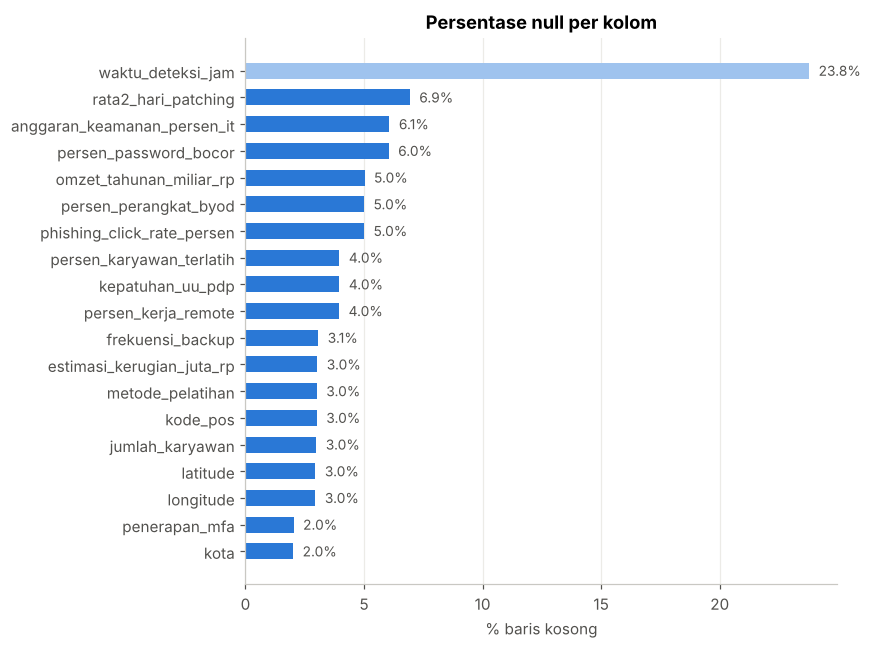

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
t = tabel_null.sort_values("persen")
warna = ["#9fc3ee" if k == "waktu_deteksi_jam" else BIRU for k in t.index]
ax.barh(t.index, t["persen"], color=warna, height=0.6)
for y, v in enumerate(t["persen"]):
    ax.text(v + 0.4, y, f"{v:.1f}%", va="center", color=ABU, fontsize=9)
ax.set_xlabel("% baris kosong")
ax.set_title("Persentase null per kolom")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Dua jenis null yang berbeda:**

- **Null struktural** — `waktu_deteksi_jam` kosong (±25%) karena perusahaan itu **memang tidak mengalami insiden**.
  Ini informasi, bukan kesalahan, jadi **tidak boleh** diisi angka.
- **Null acak** (2–6%) di 10 kolom lain — seperti responden yang melewatkan pertanyaan. Ini yang perlu ditangani.

In [26]:
tanpa_insiden = df["jumlah_insiden_12_bulan"].eq(0)
print("waktu_deteksi_jam kosong & tidak ada insiden :", (df["waktu_deteksi_jam"].isna() & tanpa_insiden).sum())
print("waktu_deteksi_jam kosong & ADA insiden       :", (df["waktu_deteksi_jam"].isna() & ~tanpa_insiden).sum())

waktu_deteksi_jam kosong & tidak ada insiden : 1217
waktu_deteksi_jam kosong & ADA insiden       : 0


In [27]:
# Ringkasan jawaban 3 soal
pd.DataFrame({
    "pertanyaan": ["Kolom numerikal", "Kolom kategorikal (termasuk ID & tanggal)", "Baris duplikat", "Sel null",
                   "Kolom yang punya null"],
    "jawaban": [len(numerik), len(kategorikal), int(n_dup), n_null, int((null > 0).sum())],
})

,pertanyaan,jawaban
0,Kolom numerikal,26
1,Kolom kategorikal (termasuk ID & tanggal),29
2,Baris duplikat,120
3,Sel null,4851
4,Kolom yang punya null,19


## 3. Merapikan Data

Logika perapihan disimpan di `sa_cli.py` agar **sama persis** antara notebook dan command line.

| Langkah | Aturan |
|---|---|
| Duplikat | Dihapus (5.120 → 5.000 baris) |
| Null berbasis logika | Tidak ada pelatihan → `metode_pelatihan = "Tidak Ada"`, `persen_karyawan_terlatih = 0`; tidak ada insiden → kerugian = 0 |
| Null numerik | Median per kelompok (skala usaha / sektor), dari baris yang sebanding |
| Null kategorikal | Modus per sektor; `kota` → "Tidak Diketahui" |
| Null struktural | `waktu_deteksi_jam` dibiarkan kosong |
| Tipe data | Ordinal → `category` berurutan, nominal → `category`, Ya/Tidak → `bool`, tanggal → `datetime` |

Versi command line:

```bash
python sa_cli.py profil     # cek kondisi data mentah
python sa_cli.py rapikan    # simpan data/security_awareness_bersih.csv
```

In [28]:
from sa_cli import rapikan_df

df_bersih = rapikan_df(df)
df_bersih.to_csv(DATA / "security_awareness_bersih.csv", index=False)

  • Hapus duplikat: 5,120 -> 5,000 baris (120 dibuang)
  • Isi berbasis aturan: 49 sel (tidak ada pelatihan/insiden -> 'Tidak Ada'/0)
  • Median per skala_usaha: jumlah_karyawan (150 sel)
  • Median per skala_usaha: omzet_tahunan_miliar_rp (250 sel)
  • Median per sektor: anggaran_keamanan_persen_it (300 sel)
  • Median per sektor: persen_kerja_remote (200 sel)
  • Median per sektor: persen_perangkat_byod (250 sel)
  • Median per skala_usaha: rata2_hari_patching (350 sel)
  • Median per sektor: persen_karyawan_terlatih (194 sel)
  • Median per sektor: phishing_click_rate_persen (250 sel)
  • Median per sektor: persen_password_bocor (300 sel)
  • Median per skala_usaha: estimasi_kerugian_juta_rp (112 sel)
  • Median koordinat per kota/provinsi: latitude & longitude (150 baris)
  • Modus per sektor: kepatuhan_uu_pdp (200 sel)
  • Modus per sektor: penerapan_mfa (100 sel)
  • Modus per sektor: metode_pelatihan (145 sel)
  • Modus per sektor: frekuensi_backup (150 sel)
  • Label 'Tidak Dik

In [29]:
print("Ukuran            :", df_bersih.shape)
print("Duplikat tersisa  :", df_bersih.duplicated().sum())
print("Null tersisa      :", df_bersih.isna().sum()[lambda s: s > 0].to_dict(), "(struktural)")
df_bersih.dtypes.astype(str).value_counts().to_frame("jumlah_kolom")

Ukuran            : (5000, 55)
Duplikat tersisa  : 0
Null tersisa      : {'waktu_deteksi_jam': 1188} (struktural)


,jumlah_kolom
category,20
float64,14
int64,12
bool,5
str,2
string,1
datetime64[us],1


In [30]:
df_bersih.describe().T.round(1)

,count,mean,min,25%,50%,75%,max,std
latitude,5000.0,-5.285333,-8.753,-6.912915,-6.22787,-6.023985,3.69177,3.065364
longitude,5000.0,108.831324,98.608,106.75789,106.88701,110.863803,140.78107,5.73805
jumlah_karyawan,5000.0,452.1428,5.0,89.0,188.0,416.25,17740.0,845.606021
omzet_tahunan_miliar_rp,5000.0,160.687956,2.09,22.0175,38.645,119.94,14918.13,491.52477
tahun_berdiri,5000.0,1997.9796,1970.0,1984.0,1999.0,2012.0,2023.0,15.952331
jumlah_cabang,5000.0,4.848,0.0,1.0,2.0,10.0,25.0,5.569012
jumlah_staf_keamanan_it,5000.0,4.7678,0.0,0.0,2.0,5.0,172.0,9.722283
anggaran_keamanan_persen_it,5000.0,8.7186,0.5,6.9,8.7,10.5,17.7,2.759055
persen_kerja_remote,5000.0,10.2436,0.0,0.0,1.85,18.2,72.5,13.685172
persen_perangkat_byod,5000.0,28.21994,0.0,18.0,28.2,38.3,83.8,14.939771


## 4. Pratinjau Insight

Pola awal dari data yang sudah rapi. Karena datanya sintetis, pola ini adalah **hipotesis** untuk diuji dengan
algoritma minggu depan (dan idealnya divalidasi dengan data survei nyata).

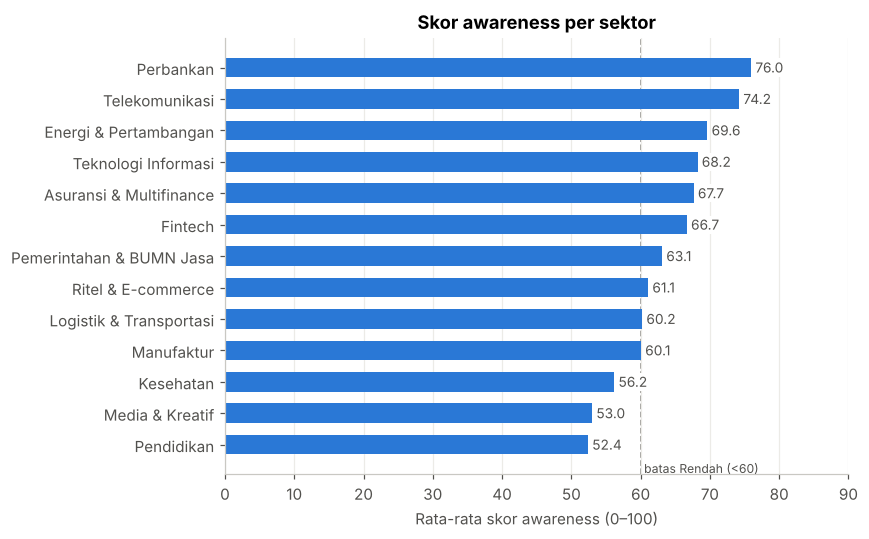

In [31]:
sektor = df_bersih.groupby("sektor", observed=True)["skor_awareness"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(sektor.index.astype(str), sektor.values, color=BIRU, height=0.62)
for y, v in enumerate(sektor.values):
    ax.text(v + 0.6, y, f"{v:.1f}", va="center", color=ABU, fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
ax.axvline(60, color="#8a8984", lw=1, ls="--", zorder=0)
ax.text(60.5, -0.9, "batas Rendah (<60)", color=ABU, fontsize=8)
ax.set_xlim(0, 90); ax.set_xlabel("Rata-rata skor awareness (0–100)")
ax.set_title("Skor awareness per sektor")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Insight 1 — Kesenjangan antarsektor.** Perbankan dan telekomunikasi rata-rata di atas 74, sedangkan media,
pendidikan, kesehatan, dan logistik di bawah 60. Padahal kesehatan dan pendidikan mengelola data pribadi sensitif
yang dilindungi UU PDP.

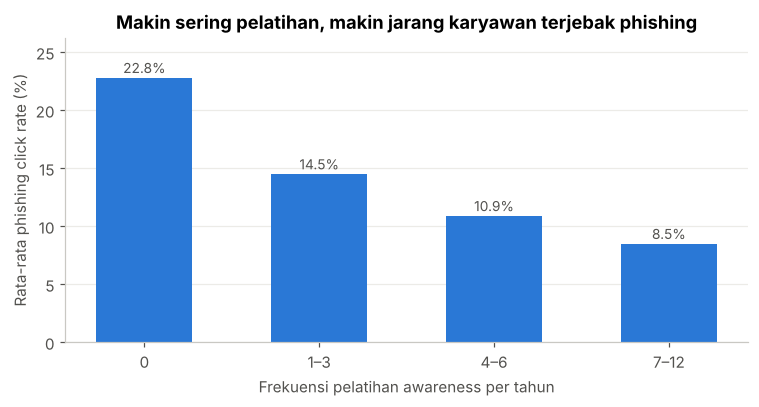

,perusahaan,click_rate,skor_awareness
frekuensi_pelatihan_per_tahun,,,
0,187,22.8,38.6
1–3,2171,14.5,58.2
4–6,1981,10.9,68.5
7–12,661,8.5,75.0


In [32]:
kelompok = pd.cut(df_bersih["frekuensi_pelatihan_per_tahun"], [-1, 0, 3, 6, 12], labels=["0", "1–3", "4–6", "7–12"])
latih = df_bersih.groupby(kelompok, observed=True).agg(
    perusahaan=("id_perusahaan", "count"),
    click_rate=("phishing_click_rate_persen", "mean"),
    skor_awareness=("skor_awareness", "mean")).round(1)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(latih.index.astype(str), latih["click_rate"], color=BIRU, width=0.55)
for x, v in enumerate(latih["click_rate"]):
    ax.text(x, v + 0.4, f"{v:.1f}%", ha="center", color=ABU, fontsize=9)
ax.set_xlabel("Frekuensi pelatihan awareness per tahun")
ax.set_ylabel("Rata-rata phishing click rate (%)")
ax.set_ylim(0, latih["click_rate"].max() * 1.15)
ax.set_title("Makin sering pelatihan, makin jarang karyawan terjebak phishing")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
latih

**Insight 2 — Pelatihan menurunkan klik phishing.** Perusahaan tanpa pelatihan punya click rate sekitar 23%,
turun menjadi sekitar 8,5% pada perusahaan yang melatih karyawan 7–12 kali per tahun.

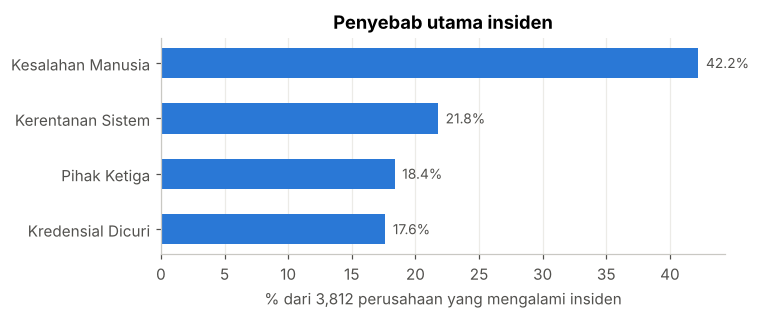

,persen
jenis_insiden_utama,
Phishing,31.4
Malware,18.4
Kebocoran Data,14.2
Social Engineering,11.8
Ransomware,11.0
Web Defacement,6.9
DDoS,6.3


In [33]:
kena = df_bersih[df_bersih["jumlah_insiden_12_bulan"] > 0]
penyebab = kena["penyebab_utama_insiden"].value_counts(normalize=True).mul(100).sort_values()
penyebab = penyebab[penyebab.index != "Tidak Ada"]

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(penyebab.index.astype(str), penyebab.values, color=BIRU, height=0.55)
for y, v in enumerate(penyebab.values):
    ax.text(v + 0.6, y, f"{v:.1f}%", va="center", color=ABU, fontsize=9)
ax.set_xlabel(f"% dari {len(kena):,} perusahaan yang mengalami insiden")
ax.set_title("Penyebab utama insiden")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

(kena["jenis_insiden_utama"].astype(str).value_counts(normalize=True)
 .mul(100).round(1).to_frame("persen"))

**Insight 3 — Faktor manusia dominan.** Kesalahan manusia adalah penyebab terbanyak dan phishing adalah jenis
insiden tersering — sejalan dengan Verizon DBIR 2025 yang mencatat elemen manusia pada sekitar 60% kebocoran.

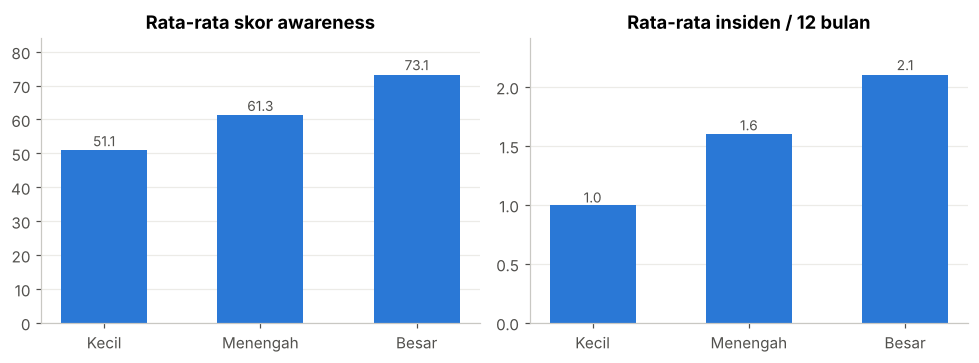

,skor_awareness,rata2_insiden,persen_awareness_rendah
skala_usaha,,,
Kecil,51.1,1.0,72.0
Menengah,61.3,1.6,46.0
Besar,73.1,2.1,17.5


In [34]:
skala = df_bersih.groupby("skala_usaha", observed=True).agg(
    skor_awareness=("skor_awareness", "mean"),
    rata2_insiden=("jumlah_insiden_12_bulan", "mean"),
    persen_awareness_rendah=("tingkat_awareness", lambda s: (s == "Rendah").mean() * 100)).round(1)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, kolom, judul in [(axes[0], "skor_awareness", "Rata-rata skor awareness"),
                         (axes[1], "rata2_insiden", "Rata-rata insiden / 12 bulan")]:
    ax.bar(skala.index.astype(str), skala[kolom], color=BIRU, width=0.55)
    for x, v in enumerate(skala[kolom]):
        ax.text(x, v * 1.02, f"{v:.1f}", ha="center", color=ABU, fontsize=9)
    ax.set_ylim(0, skala[kolom].max() * 1.15)
    ax.set_title(judul); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
skala

**Insight 4 — Paradoks skala.** Perusahaan besar paling sadar keamanan, tetapi juga paling sering mengalami insiden
(lebih banyak karyawan, sistem, dan target). Artinya **jumlah insiden saja bukan ukuran awareness yang adil** —
perlu dinormalisasi atau dikombinasikan dengan fitur lain. Sementara itu, 72% usaha kecil berada di level awareness *Rendah*.

In [35]:
kepatuhan = pd.concat({
    "Indeks KAMI": df_bersih["kategori_indeks_kami"].value_counts(normalize=True),
    "UU PDP": df_bersih["kepatuhan_uu_pdp"].value_counts(normalize=True),
}).mul(100).round(1).to_frame("persen")
kepatuhan

persen
Indeks KAMI Pemenuhan Kerangka Kerja Dasar    50.6
            Cukup Baik                        31.2
            Tidak Layak                       14.6
            Baik                               3.6
UU PDP      Patuh                             40.1
            Sebagian                          34.1
            Belum                             25.8

**Insight 5 — Kesiapan regulasi masih rendah.** Sekitar 65% perusahaan berada di bawah level *Cukup Baik* pada
Indeks KAMI, dan sekitar 60% belum sepenuhnya patuh UU PDP.

In [36]:
fitur = ["persen_karyawan_terlatih", "frekuensi_pelatihan_per_tahun", "phishing_click_rate_persen",
         "skor_indeks_kami", "anggaran_keamanan_persen_it", "jumlah_insiden_12_bulan"]
df_bersih[fitur + ["skor_awareness"]].corr()["skor_awareness"].drop("skor_awareness").sort_values().round(2).to_frame("korelasi_dgn_skor_awareness")

,korelasi_dgn_skor_awareness
phishing_click_rate_persen,-0.76
jumlah_insiden_12_bulan,-0.25
frekuensi_pelatihan_per_tahun,0.47
anggaran_keamanan_persen_it,0.61
persen_karyawan_terlatih,0.69
skor_indeks_kami,0.77


**Insight 6 — Kandidat fitur terkuat.** Skor awareness paling erat dengan *phishing click rate* (negatif) dan
skor Indeks KAMI (positif). Ini kandidat fitur utama untuk model klasifikasi `tingkat_awareness` minggu depan.

## 5. Kesimpulan & Langkah Berikutnya

| Soal | Jawaban |
|---|---|
| Jenis data | 26 kolom numerikal, 29 kolom non-numerik (25 kategorikal fitur + `kode_pos` + 2 identitas + 1 tanggal) |
| Tipe data kategorikal | Terbaca sebagai `str`/`object`; dirapikan menjadi `category` (ordinal berurutan) atau `bool`. Bukan `float`, dan `void` tidak dipakai di pandas |
| Duplikat & null | 120 baris duplikat; 4.851 sel null di 19 kolom; 1.217 di antaranya null struktural (`waktu_deteksi_jam`) yang tetap dibiarkan |

**Langkah berikutnya:**
1. **Klasifikasi** `tingkat_awareness` dengan Decision Tree → jalankan `python klasifikasi_awareness.py`.
2. **Clustering** profil keamanan perusahaan (K-Means) → segmentasi untuk program awareness yang tepat sasaran.